# [실습] 리뷰 속성 표 — 무엇 때문에 불만인가

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 질문과 데이터

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">비정형 데이터(자연어) · LLM 라벨링과 속성 코드북</div>
<h1 style="color:#000000;margin:10px 0">리뷰 속성 표 — 무엇 때문에 불만인가</h1>
<div style="font-size:1.05em;color:#656565">Qwen3-4B 로 라벨링한 리뷰 1,000건과 전임 담당자의 출력으로 코드북 적용, 출력 확인, 분모 결정, 구간 비교를 연습합니다. 전임 담당자의 「사이즈 불만 15.93%」도 고칩니다</div>
</div>

**핵심 질문** 리뷰의 불만은 어느 속성에 많고, LLM 라벨로 구한 비율을 그대로 써도 될까요?

이론에서 본 라벨 과정을 실제 쇼핑 리뷰에 직접 해 봅니다. 계산하는 코드는 모두 준비되어 있습니다.

1. **코드북으로 라벨 정하기**: 리뷰 5건에 코드북 v1 로 라벨을 정하고 Qwen3-4B 의 라벨과 비교합니다.
2. **LLM 출력 확인**: 출력 6건에서 형식을 어긴 출력과 보류할 라벨을 찾습니다.
3. **분모와 비율**: 리뷰 200건의 검증 결과로 품질 부정 비율을 구합니다.
4. **전임 담당자의 집계 고치기**: 「사이즈 불만 15.93%」의 틀린 곳 두 개를 찾아 고칩니다.
5. **만족한 리뷰의 불만**: 별점 4·5점 리뷰에서 불만이 가장 많은 속성을 찾고 구간이 겹치는지로 순위를 판단합니다.

단계마다 코드를 실행해 출력을 읽고 직접 해 보기에서 `MY_` 로 시작하는 변수에 답을 적습니다. 바로 아래 확인 셀을 실행하면 결과가 나옵니다.

**실행 안내**

- LMS 에서는 셀을 위에서부터 차례로 실행합니다. GPU 는 필요 없습니다.
- Colab 이나 내 컴퓨터에서 열었다면 맨 위 설치 셀부터 실행합니다. 처음 한 번은 원자료를 받느라 30초 안팎 걸립니다.
- 단계 2 의 [선택] 셀만 GPU 를 씁니다. GPU 가 없으면 그 셀은 건너뛴다는 안내만 출력합니다.
- 확인 셀은 변수를 아직 채우지 않아도 오류 없이 안내만 출력합니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/f/f7/NachoKamenov-Humansin_the_LoopDataannotators_discussing_the_correct_labeling_of_a_dataset-3543x2362.jpg/960px-NachoKamenov-Humansin_the_LoopDataannotators_discussing_the_correct_labeling_of_a_dataset-3543x2362.jpg" alt="두 사람이 모니터 앞에 함께 앉아 모니터 하나를 보며 라벨을 두고 이야기하는 사진" width="560" height="373"/>
<p align="center"><em>▲ 데이터 라벨러 두 사람이 모니터 하나를 보며 라벨을 맞추는 모습 (출처: Wikimedia Commons, Nacho Kamenov & Humans in the Loop, CC BY 4.0)</em></p>

In [1]:
# 실습 준비: 설치·폰트. 폰트 설치는 Colab 에서만 합니다
#  이 실습은 새로 설치하는 패키지가 없습니다.
#  transformers · torch · numpy · pandas · pyarrow · matplotlib 은 Colab 기본 버전을 그대로 씁니다.
#  과정 결과는 transformers 5.3.0 · torch 2.11.0 에서 만들었습니다. 버전이 다르면 아래에 참고 안내가 나옵니다.
import os, sys, math, time
import subprocess
IN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import warnings; warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")   # 토크나이저 경고가 나오지 않게

# 한글 폰트: Colab 이면 나눔고딕을 설치한 뒤 그 ttf 를 폰트 목록에 **직접** 등록한다.
#  설치는 디스크에 파일만 만든다. 이미 떠 있는 폰트 목록은 그 사실을 모르므로 addfont 로
#  등록해야 이름이 보인다(등록하지 않으면 DejaVu Sans 로 밀려 한글이 전부 □ 로 나온다).
import glob, shutil
if IN_COLAB and shutil.which("apt-get"):
    subprocess.run(["apt-get", "-y", "-qq", "install", "fonts-nanum"], check=False)
for _p in glob.glob("/usr/share/fonts/truetype/nanum/Nanum*.ttf"):   # 설치 여부와 무관하게 한 번
    try: fm.fontManager.addfont(_p)
    except Exception: pass
try: fm._get_font.cache_clear()
except Exception: pass
installed = {f.name for f in fm.fontManager.ttflist}
FONT = next((n for n in ["Pretendard", "Apple SD Gothic Neo", "NanumGothic"] if n in installed), "DejaVu Sans")
plt.rcParams["font.family"] = FONT
plt.rcParams["axes.unicode_minus"] = FONT in {"Pretendard", "DejaVu Sans"}   # 나머지 폰트에는 U+2212 가 없다
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}   # 그림마다 폭이 깎이지 않게
plt.rcParams["figure.dpi"] = plt.rcParams["savefig.dpi"] = 150       # 폭 FIG_W x 150dpi = 1500px 고정
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({"font.size": 11, "axes.titlesize": 15, "axes.labelsize": 12,
                     "legend.fontsize": 11, "figure.titlesize": 17, "font.weight": "regular",
                     "text.color": "black", "axes.labelcolor": "black", "axes.titlecolor": "black",
                     "axes.edgecolor": "#757575", "xtick.color": "#757575", "ytick.color": "#757575",
                     "xtick.labelcolor": "black", "ytick.labelcolor": "black",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})

# 이 실습의 그림 전체가 함께 쓰는 색: 기준선=남색, 관측=파랑, 강조=하늘색, 문맥=회색
COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",
       "회색": "#757575", "연회색": "#B3B3B3"}
FIG_W = 10.0     # 캔버스 폭은 이 실습의 그림 모두 이 값으로 고정하고 높이만 그림마다 조절한다

from importlib.metadata import version as _ver, PackageNotFoundError
_want = {"transformers": "5.3.0", "torch": "2.11.0"}
_have = {}
for _name in _want:
    try:
        _have[_name] = _ver(_name)
    except PackageNotFoundError:
        _have[_name] = "없음"
print("사용 폰트:", FONT, "| 색 팔레트 준비 완료 |", " · ".join(f"{k} {v}" for k, v in _have.items()))
_diff = [k for k in ("transformers", "torch") if not _have[k].startswith(_want[k])]
if _diff:
    print("참고: 과정 결과는 " + " · ".join(f"{k} {_want[k]}" for k in _diff) + " 에서 만들었습니다. 단계 2 의 [선택] 셀에서 GPU 로"
          " 모델을 다시 호출하면 라벨 몇 개가 저장된 라벨과 다를 수 있습니다.")

사용 폰트: NanumGothic | 색 팔레트 준비 완료 | transformers 5.20.2 · torch 2.11.0+cpu
참고: 과정 결과는 transformers 5.3.0 에서 만들었습니다. 단계 2 의 [선택] 셀에서 GPU 로 모델을 다시 호출하면 라벨 몇 개가 저장된 라벨과 다를 수 있습니다.


## 자료 준비

자료는 이론과 같습니다. 분석 단위는 리뷰 한 건입니다.

| 자료 | 이 실습에서 쓰는 것 |
|---|---|
| 네이버 쇼핑 리뷰(bab2min/corpus, 별점 1·2·4·5점) | 20만 건 가운데 무작위 2만 건(시드 0)의 별점 · 본문 |
| Qwen3-4B 라벨(과정 결과) | 2만 건의 선택형 극성, 앞 1,000건의 속성 라벨 · 근거 텍스트 · 검증 상태 · 시도 수 |
| 전임 담당자의 출력(과정 결과) | Qwen2.5-0.5B 가 앞 2,000건에 한 번씩 낸 원 출력 글 |

**과정 결과**는 이 교육 과정이 같은 표본 · 같은 프롬프트로 미리 만들어 둔 파일입니다. 이 실습은 모델을 다시 호출하지 않고 저장된 결과를 읽습니다. 저장된 라벨에는 행 번호와 라벨만 있어, 본문과 별점은 행 번호로 원자료와 합칩니다.

검사 함수 3개도 이 셀이 정의합니다.

- `check_output(원 출력, 원문)`: JSON 으로 읽히는지(파싱), 키와 값이 스키마의 허용 목록 안인지 확인합니다.
- `evidence_in_text(근거 텍스트, 원문)`: 근거 텍스트가 원문 안에 글자 그대로 이어져 있는지 확인합니다.
- `extract_json(원 출력)`: 원 출력 글에서 JSON 부분을 추출합니다. `check_output` 이 내부에서 호출합니다.

아래 「자료 준비」 셀은 읽고 실행만 합니다.

In [2]:
# 자료 준비: 읽고 실행만 합니다
# 리뷰 원자료 · Qwen3-4B 라벨 · 전임 담당자의 출력을 읽고, 코드북 v1 과 검사 함수를 정의합니다. 모델은 호출하지 않습니다
import os, re, json, math, time, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_FILES = {
    "reviews": ("https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt",
                "naver_shopping.txt",
                "dc4d1aca0a148671cbe80bcb81962eee297370acab42be93c1617ce9336479c0",
                "https://github.com/bab2min/corpus/tree/master/sentiment"),
}
DATA_URL = "https://github.com/studio-js/korean-cx-text/raw/main/data"   # 과정 결과(LLM 라벨) 파일 주소
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"  # 원자료의 과정 복제본(원 출처와 같은 바이트)
SUBDIRS = ("", "cache", "raw", "processed")  # 자료 폴더 아래에서 찾는 차례


def data_dir():
    # 자료 최상위 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 최상위 폴더 → cache/ → raw/ → processed/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in SUBDIRS:
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    # 파일의 SHA-256 16진 문자열
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True (실패하면 세 번까지 다시 시도)
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:  # network error: retry
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name, sha=None, strict=False):
    # 로컬에 있으면 그 경로, 없으면 url 에서 받아 SHA-256 확인 뒤 최상위 폴더/cache/ 에 두고 경로를 반환함
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        if not _download(url, path):
            return None
        if strict and sha and sha256_of(path + ".part") != sha:
            os.remove(path + ".part")
            raise RuntimeError(f"받은 {name} 의 SHA-256 이 맞지 않습니다. 다시 실행해 보세요.")
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 본문의 수와 다를 수 있습니다(데이터 페이지: {page})")
    return path


def fetch_precomputed(name, sha=None):
    # 과정 결과 파일 경로: 로컬을 먼저 보고, 없으면 DATA_URL/name 에서 받음(sha 를 주면 맞지 않을 때 멈춤)
    path = _fetch(f"{DATA_URL}/{name}", name, sha, strict=True)
    if path is None:
        raise RuntimeError(f"과정 결과 파일 {name} 을 받지 못했습니다. 이 파일은 다른 경로로 만들 수 없습니다."
                           " 강사에게 받은 파일을 이 노트북과 같은 폴더의 nlp_data/ 에 두고 이 셀을 다시 실행합니다")
    return path


def rnd(x, digits):
    # 십진 값 기준 반올림(끝자리 5 는 올림): 본문의 수와 같은 반올림 방식
    x = float(x)
    if not math.isfinite(x):
        return x
    return float(Decimal(f"{x:.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


ASPECTS = ["배송", "품질", "사이즈", "가격", "교환/환불", "기타"]
POLARITIES = ["긍정", "부정", "중립"]
OVERALL = ["긍정", "부정"]

# 리뷰 속성 코드북 v1: 속성마다 이름 · 정의 · 포함 기준 · 제외 기준
CODEBOOK_V1 = [
    {"속성": "배송", "정의": "주문한 물건이 도착하기까지의 과정",
     "포함": "속도·지연, 택배, 포장·박스 상태, 오배송",
     "제외": "제품 자체의 흠집·불량(→ 품질)"},
    {"속성": "품질", "정의": "제품 자체의 상태와 성능",
     "포함": "불량, 마감, 내구성, 맛·신선도, 성능, 디자인",
     "제외": "크기·치수(→ 사이즈), 포장 상태(→ 배송)"},
    {"속성": "사이즈", "정의": "크기·길이·치수가 맞는지",
     "포함": "크기, 길이, 핏, 양",
     "제외": "무게감·두께 같은 재질 느낌(→ 품질)"},
    {"속성": "가격", "정의": "값과 가성비",
     "포함": "싸다·비싸다, 가성비, 할인",
     "제외": "환불 금액(→ 교환/환불)"},
    {"속성": "교환/환불", "정의": "교환·반품·환불·취소 절차",
     "포함": "교환·반품, 환불, 주문 취소",
     "제외": "처음 배송 지연(→ 배송)"},
    {"속성": "기타", "정의": "위 다섯에 들지 않는 구체적 평가",
     "포함": "판매자 응대, 사은품 등",
     "제외": "속성이 드러나지 않는 감탄(예: 좋아요)은 라벨 없음"},
]
BOUNDARY_RULE = "박스·포장 파손은 배송, 제품 자체의 흠집·불량은 품질."

# JSON 스키마: 출력이 지켜야 할 키와 허용 목록
SCHEMA_V1 = {
    "type": "object",
    "required": ["overall", "aspects"],
    "properties": {
        "overall": {"enum": OVERALL},
        "aspects": {
            "type": "array",
            "items": {
                "type": "object",
                "required": ["aspect", "polarity", "evidence"],
                "properties": {
                    "aspect": {"enum": ASPECTS},
                    "polarity": {"enum": POLARITIES},
                    "evidence": {"type": "string"},
                },
            },
        },
    },
}


def extract_json(raw):
    """First {...} block that parses; None if none."""
    s = raw.strip()
    s = re.sub(r"^```(?:json)?\s*|\s*```$", "", s)
    start = s.find("{")
    while start != -1:
        depth = 0
        for i in range(start, len(s)):
            if s[i] == "{":
                depth += 1
            elif s[i] == "}":
                depth -= 1
                if depth == 0:
                    try:
                        return json.loads(s[start:i + 1])
                    except json.JSONDecodeError:
                        break
        start = s.find("{", start + 1)
    return None


def schema_errors(obj, schema=SCHEMA_V1):
    """Small validator for this schema family (object / array / enum / string / required)."""
    errs = []

    def walk(x, sch, path):
        if "enum" in sch:
            if x not in sch["enum"]:
                errs.append(f"{path} 값 {x!r} 는 허용 목록 밖")
            return
        t = sch.get("type")
        if t == "object":
            if not isinstance(x, dict):
                errs.append(f"{path} 는 객체여야 함")
                return
            for k in sch.get("required", []):
                if k not in x:
                    errs.append(f"{path}.{k} 없음")
            for k, sub in sch.get("properties", {}).items():
                if k in x:
                    walk(x[k], sub, f"{path}.{k}")
        elif t == "array":
            if not isinstance(x, list):
                errs.append(f"{path} 는 목록이어야 함")
                return
            for i, item in enumerate(x):
                walk(item, sch["items"], f"{path}[{i}]")
        elif t == "string" and not isinstance(x, str):
            errs.append(f"{path} 는 문자열이어야 함")

    walk(obj, schema, "$")
    return errs


def _squash(s):
    return re.sub(r"\s+", " ", s).strip()


def evidence_in_text(evidence, text):
    """Evidence must be a non-empty substring of the original review (whitespace runs collapsed)."""
    if not isinstance(evidence, str):
        return False
    ev = _squash(evidence)
    return bool(ev) and ev in _squash(text)


def check_output(raw, text, schema=SCHEMA_V1):
    """-> dict(parsed, errors, ok). ok = parsed and schema-valid."""
    obj = extract_json(raw)
    if obj is None:
        return {"parsed": None, "errors": ["JSON 파싱 실패"], "ok": False}
    errs = schema_errors(obj, schema)
    return {"parsed": obj, "errors": errs, "ok": not errs}


# 리뷰 20만 건(별점 → 별점 극성)과 리뷰 표본 2만 건(시드 0, 표본 안의 차례 = rank)
_rows = [ln.split("\t", 1) for ln in open(fetch_raw("reviews"), encoding="utf-8").read().split("\n") if ln]
REVIEWS = pd.DataFrame(_rows, columns=["별점", "본문"])
REVIEWS.insert(0, "row_id", range(len(REVIEWS)))                 # 원자료의 행 번호(0부터)
REVIEWS["별점"] = REVIEWS["별점"].astype(int)
REVIEWS["극성"] = np.where(REVIEWS["별점"] <= 2, "부정", "긍정")   # 별점 극성: 1·2점 부정, 4·5점 긍정
SAMPLE = REVIEWS.sample(n=20000, random_state=0).reset_index(drop=True)
SAMPLE.insert(1, "rank", range(len(SAMPLE)))

# Qwen3-4B 라벨(과정 결과): 2만 건의 선택형 극성(overall)과 앞 1,000건의 속성 라벨
_lab = pd.read_parquet(fetch_precomputed("llm_review_labels.parquet"))
MODEL_INFO = f"{_lab['model'].iloc[0].split('/')[-1]}(버전 {_lab['model_revision'].iloc[0][:8]})"
OVERALL_20K = _lab[["row_id", "overall"]].merge(SAMPLE[["row_id", "별점", "극성"]], on="row_id")
LABELS_1000 = (_lab.loc[_lab["aspects_done"], ["row_id", "status", "tries", "aspects_json"]]
               .merge(SAMPLE[["row_id", "rank", "별점", "극성", "본문"]], on="row_id")
               .sort_values("rank").reset_index(drop=True))
LABELS_1000["status"] = LABELS_1000["status"].replace({"재요청 통과": "재시도 통과"})   # 상태값 이름을 본문과 같게
LABELS_1000["labels"] = LABELS_1000["aspects_json"].map(json.loads)   # 리뷰마다 라벨 목록(속성 · 극성 · 근거 텍스트 · evidence_ok)
LABELS_1000["tries"] = LABELS_1000["tries"].astype(int)

# 전임 담당자의 출력(과정 결과): Qwen2.5-0.5B 가 앞 2,000건에 한 번씩 낸 원 출력 글. 재시도는 없었습니다
_pred = pd.read_parquet(fetch_precomputed("llm_review_predecessor.parquet"))
PRED = (_pred[["row_id", "raw", "model"]].merge(SAMPLE[["row_id", "rank", "별점", "본문"]], on="row_id")
        .sort_values("rank").reset_index(drop=True))
N_SENT = len(PRED)                                                # 전임 담당자가 모델에 보낸 리뷰 수

_st = LABELS_1000["status"].value_counts()
print(f"준비 끝: Qwen3-4B 라벨 리뷰 {len(LABELS_1000):,}건 · 전임 담당자의 출력 {N_SENT:,}건")
print(f"리뷰 {len(REVIEWS):,}건 → 리뷰 표본 {len(SAMPLE):,}건(시드 0) · 선택형 극성 {OVERALL_20K['overall'].notna().sum():,}건")
print(f"속성 라벨: 표본의 앞 {len(LABELS_1000):,}건 · 모델 {MODEL_INFO} · 프롬프트 버전 aspect-v1")
print(f"검증 상태: 통과 {_st.get('통과', 0)}건 · 재시도 통과 {_st.get('재시도 통과', 0)}건 · 라벨 실패 {_st.get('기타', 0)}건")
print(f"전임 담당자: {PRED['model'].iloc[0].split('/')[-1]} · 표본의 앞 {N_SENT:,}건 · 재시도 없음")
print("코드북 v1 의 속성 6개: " + " · ".join(ASPECTS))
print("Qwen3-4B 의 라벨은 정답이 아니라 모델 하나의 판단입니다")

준비 끝: Qwen3-4B 라벨 리뷰 1,000건 · 전임 담당자의 출력 2,000건
리뷰 200,000건 → 리뷰 표본 20,000건(시드 0) · 선택형 극성 20,000건
속성 라벨: 표본의 앞 1,000건 · 모델 Qwen3-4B-Instruct-2507(버전 cdbee75f) · 프롬프트 버전 aspect-v1
검증 상태: 통과 873건 · 재시도 통과 108건 · 라벨 실패 19건
전임 담당자: Qwen2.5-0.5B-Instruct · 표본의 앞 2,000건 · 재시도 없음
코드북 v1 의 속성 6개: 배송 · 품질 · 사이즈 · 가격 · 교환/환불 · 기타
Qwen3-4B 의 라벨은 정답이 아니라 모델 하나의 판단입니다


리뷰 1,000건 가운데 873건은 첫 시도에 형식을 통과했고 19건은 재시도 뒤에도 형식을 어겨 라벨 실패입니다. 저장된 상태값으로는 라벨 실패가 「기타」로 적혀 있습니다. 속성 「기타」와 다른 값입니다.

같은 리뷰도 모델이나 프롬프트가 바뀌면 라벨이 달라질 수 있습니다. 그래서 비율끼리 비교할 때 모델 이름 · 모델 버전 · 프롬프트 버전이 다르면 두 비율의 차이가 불만의 차이인지 라벨의 차이인지 알 수 없습니다. 이 라벨의 모델은 Qwen3-4B-Instruct-2507(버전 cdbee75f)입니다. 프롬프트 버전은 aspect-v1 입니다.

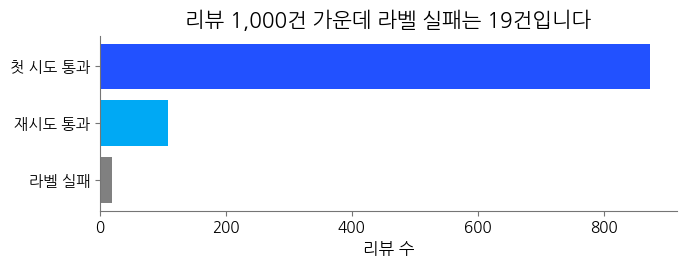

In [3]:
# 자료 준비 · 그림: 리뷰 1,000건의 검증 상태
counts = LABELS_1000["status"].value_counts().reindex(["통과", "재시도 통과", "기타"], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(["첫 시도 통과", "재시도 통과", "라벨 실패"], counts.values, color=["#2251FF", "#00A9F4", "gray"])
ax.invert_yaxis()
ax.set_xlabel("리뷰 수")
ax.set_title(f"리뷰 1,000건 가운데 라벨 실패는 {counts['기타']}건입니다")
plt.show()

## 단계 1 코드북으로 라벨 정하기

리뷰 한 건의 라벨은 무엇을 평가했는지(속성)와 그 평가가 긍정 · 부정 · 중립 가운데 무엇인지(극성)의 쌍입니다. 코드북 v1 은 속성 6개의 이름 · 정의 · 포함 기준 · 제외 기준을 정한 표입니다. Qwen3-4B 에 보낸 프롬프트도 같은 코드북을 썼습니다.

| 속성 | 정의 | 포함 기준 | 제외 기준 |
|---|---|---|---|
| 배송 | 주문한 물건이 도착하기까지의 과정 | 속도·지연, 택배, 포장·박스 상태, 오배송 | 제품 자체의 흠집·불량(→ 품질) |
| 품질 | 제품 자체의 상태와 성능 | 불량, 마감, 내구성, 맛·신선도, 성능, 디자인 | 크기·치수(→ 사이즈), 포장 상태(→ 배송) |
| 사이즈 | 크기·길이·치수가 맞는지 | 크기, 길이, 핏, 양 | 무게감·두께 같은 재질 느낌(→ 품질) |
| 가격 | 값과 가성비 | 싸다·비싸다, 가성비, 할인 | 환불 금액(→ 교환/환불) |
| 교환/환불 | 교환·반품·환불·취소 절차 | 교환·반품, 환불, 주문 취소 | 처음 배송 지연(→ 배송) |
| 기타 | 위 5개 속성에 속하지 않는 구체적 평가 | 판매자 응대, 사은품 등 | 속성이 드러나지 않는 감탄(예: 좋아요)은 라벨 없음 |

- 극성은 긍정 · 부정 · 중립 가운데 하나입니다.
- 프롬프트에는 「박스·포장 파손은 배송, 제품 자체의 흠집·불량은 품질」이라는 구분도 있습니다.
- 한 리뷰에 같은 속성이 두 번 나와도 라벨 하나로 적으면 됩니다. 확인 셀은 (속성, 극성)이 같은지만 비교합니다.

이름만 있으면 애매한 리뷰를 사람마다 다르게 나눕니다. 포함 기준과 제외 기준이 있으면 그런 리뷰도 속성 하나로 정해집니다.

아래 셀이 그리는 그림에서는 라벨 실패를 뺀 리뷰 981건을 라벨이 몇 개인지에 따라 구분했습니다. (속성, 극성)이 같은 라벨은 하나로 집계했습니다.

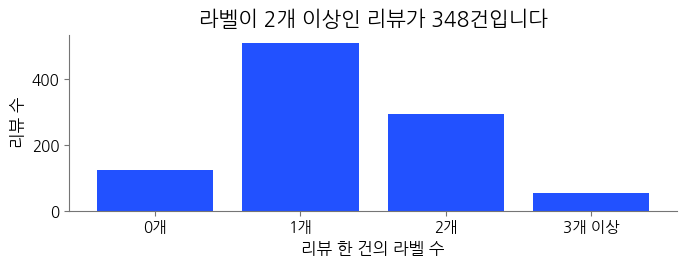

In [4]:
# 단계 1 · 그림: 리뷰 한 건의 라벨 수(라벨 실패 리뷰 제외, 3개 이상은 한 막대)
done = LABELS_1000[LABELS_1000["status"] != "기타"]
n_lab = done["labels"].map(lambda labs: min(len({(x["aspect"], x["polarity"]) for x in labs}), 3))
counts = n_lab.value_counts().reindex([0, 1, 2, 3], fill_value=0)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(["0개", "1개", "2개", "3개 이상"], counts.values, color="#2251FF")
ax.set_xlabel("리뷰 한 건의 라벨 수")
ax.set_ylabel("리뷰 수")
ax.set_title(f"라벨이 2개 이상인 리뷰가 {counts[2] + counts[3]}건입니다")
plt.show()

리뷰 981건 가운데 348건은 라벨이 2개 이상이고, 124건은 라벨이 없습니다. 라벨이 없는 리뷰도 분석 대상에서 빠지지 않습니다.

아래 셀은 리뷰 1,000건에서 고른 리뷰 5건의 별점과 원문을 출력합니다. Qwen3-4B 의 라벨은 확인 셀에서 보여 줍니다. 먼저 코드북만 보고 직접 정합니다.

In [5]:
# 단계 1: 리뷰 1,000건에서 고른 리뷰 5건(행 번호 · 별점 · 원문)
STEP1_IDS = [161542, 43403, 32284, 144586, 37400]
BY_ID = LABELS_1000.set_index("row_id")


def show_review(rid):
    # 리뷰 한 건의 행 번호 · 별점 · 원문을 한 줄로 출력합니다
    r = BY_ID.loc[rid]
    print(f"리뷰 {rid} · 별점 {r['별점']} · {r['본문']}")


print("리뷰 5건. 라벨은 코드북 v1 의 속성 6개와 극성 3가지로 정합니다")
for rid in STEP1_IDS:
    show_review(rid)

리뷰 5건. 라벨은 코드북 v1 의 속성 6개와 극성 3가지로 정합니다
리뷰 161542 · 별점 5 · 배송빠르고 좀 부실하긴 하지만 가격대비 좋아요
리뷰 43403 · 별점 2 · 포장이 많이 아쉬우나 맛은좋아요
리뷰 32284 · 별점 2 · 찌그러져서 왔어요 귀찮아서 그냥 씁니다
리뷰 144586 · 별점 2 · 만족해요 추천 추천
리뷰 37400 · 별점 1 · 교환이 너무 늦었네요 ㅜ


**직접 해 보기: 리뷰 5건의 라벨 정하기**

리뷰마다 라벨 목록을 `MY_LABELS` 에 적습니다. 키는 리뷰 번호(행 번호), 값은 `("속성", "극성")` 의 목록입니다. 라벨이 없는 리뷰는 빈 목록 `[]` 입니다.

- 예: 이론의 예시 리뷰 2 라면 값은 `[("배송", "긍정"), ("품질", "부정")]` 입니다.
- 별점은 참고만 합니다. 별점 5점 리뷰에도 부정 라벨이 있을 수 있습니다.
- 애매한 리뷰는 속성 하나로 정한 뒤, 코드북의 어느 기준에 그 결정을 추가할지 생각해 둡니다.

확인 셀은 Qwen3-4B 의 라벨과 같은 것 · 다른 것을 리뷰마다 출력합니다. Qwen3-4B 의 라벨은 정답이 아닙니다. 다르면 코드북의 어느 기준으로 정했는지 다시 읽어 봅니다.

In [6]:
# 단계 1 · 직접 해 보기: {리뷰 번호: [("속성", "극성"), …]}
MY_LABELS = {161542: [("배송", "긍정"),("품질", "부정"),("가격", "긍정")],
            43403: [("배송", "부정"),("품질", "긍정")],
            32284: [("품질", "부정")],
            144586: [],
            37400: [("교환/환불", "부정")]
            }

In [7]:
# 단계 1 · 확인 셀: MY_LABELS 를 Qwen3-4B 의 라벨(정답이 아님)과 비교합니다
QWEN = {rid: {(x["aspect"], x["polarity"]) for x in BY_ID.loc[rid, "labels"]} for rid in STEP1_IDS}
NOTE = {43403: "포장은 배송의 포함 기준(포장·박스 상태)에 있는 말입니다",
        32284: "애매한 리뷰: 무엇이 찌그러졌는지 원문에 없습니다. 정한 속성의 포함 기준에 이 경우를 추가합니다",
        144586: "감탄만 있는 리뷰: 무엇이 좋은지 말하지 않아 라벨이 없습니다. 기타의 제외 기준과 같습니다"}


def fmt(pairs):
    return " ".join(f"({a}, {p})" for a, p in sorted(pairs)) or "없음"


def check_labels(my):
    if not my:
        print("아직 채우지 않았습니다. 위 셀의 MY_LABELS 를 채운 뒤 다시 실행합니다")
        return
    if [k for k in my if k not in STEP1_IDS]:
        print(f"고칠 것: 키는 위에 출력한 리뷰 번호 {STEP1_IDS} 가운데 하나로 적습니다")
        return
    pairs = [p for v in my.values() for p in v]
    if not all(isinstance(p, tuple) and len(p) == 2 and p[0] in ASPECTS and p[1] in POLARITIES for p in pairs):
        print('고칠 것: 라벨은 ("품질", "부정") 처럼 적습니다. 속성은 코드북 v1 의 6개, 극성은 긍정 · 부정 · 중립입니다')
        return
    if len(my) < len(STEP1_IDS):
        print(f"리뷰 {len(STEP1_IDS)}건 가운데 {len(my)}건만 적었습니다. 나머지도 적은 뒤 다시 실행합니다")
    same = sum(set(my[k]) == QWEN[k] for k in my)
    print(f"Qwen3-4B 와 라벨이 모두 같은 리뷰 {same}건 / 적은 리뷰 {len(my)}건 · Qwen3-4B 의 라벨은 정답이 아닙니다")
    for rid in [k for k in STEP1_IDS if k in my]:
        mine, qwen = set(my[rid]), QWEN[rid]
        print(f"리뷰 {rid}: 같음 {fmt(mine & qwen)} · 나만 {fmt(mine - qwen)} · Qwen3-4B 만 {fmt(qwen - mine)}")
        if rid in NOTE:
            print("  " + NOTE[rid])


check_labels(globals().get("MY_LABELS", {}))

Qwen3-4B 와 라벨이 모두 같은 리뷰 4건 / 적은 리뷰 5건 · Qwen3-4B 의 라벨은 정답이 아닙니다
리뷰 161542: 같음 (가격, 긍정) (배송, 긍정) (품질, 부정) · 나만 없음 · Qwen3-4B 만 없음
리뷰 43403: 같음 (배송, 부정) (품질, 긍정) · 나만 없음 · Qwen3-4B 만 없음
  포장은 배송의 포함 기준(포장·박스 상태)에 있는 말입니다
리뷰 32284: 같음 (품질, 부정) · 나만 없음 · Qwen3-4B 만 (가격, 중립)
  애매한 리뷰: 무엇이 찌그러졌는지 원문에 없습니다. 정한 속성의 포함 기준에 이 경우를 추가합니다
리뷰 144586: 같음 없음 · 나만 없음 · Qwen3-4B 만 없음
  감탄만 있는 리뷰: 무엇이 좋은지 말하지 않아 라벨이 없습니다. 기타의 제외 기준과 같습니다
리뷰 37400: 같음 (교환/환불, 부정) · 나만 없음 · Qwen3-4B 만 없음


<details class="lms-extra"><summary>자세히 — 예시 답</summary>

```text
MY_LABELS = {161542: [("배송", "긍정"), ("품질", "부정"), ("가격", "긍정")],
             43403: [("배송", "부정"), ("품질", "긍정")], 32284: [("품질", "부정")],
             144586: [], 37400: [("교환/환불", "부정")]}
```

- 리뷰 161542 는 별점 5점이지만 「좀 부실하긴 하지만」이 품질 부정입니다. 라벨이 3개인 리뷰입니다.
- 리뷰 43403 은 별점 2점이지만 「맛은좋아요」가 품질 긍정입니다. 맛은 품질의 포함 기준에 있습니다.
- 리뷰 144586 은 무엇이 좋은지 말하지 않은 감탄이라 라벨이 없습니다.
- 리뷰 32284 는 이론의 예시 리뷰 8 처럼 무엇이 찌그러졌는지 원문에 없는 애매한 리뷰입니다. 품질로 정했다면 품질의 포함 기준에 「파손 대상이 원문에 없으면 품질」을 더합니다. 배송으로 정해도 되지만 어느 쪽으로 정했는지가 코드북에 있어야 사람마다 같은 라벨이 나옵니다.

Qwen3-4B 는 리뷰 32284 에 (가격, 중립)도 냈습니다. 근거 텍스트는 「귀찮아서 그냥 씁니다」인데 값이나 가성비를 말한 구절이 아닙니다. 나머지 4건은 예시 답과 같습니다.

</details>

## 단계 2 LLM 출력 확인

LLM 의 출력은 글입니다. 집계하기 전에 출력마다 형식과 근거 텍스트를 확인합니다.

- **형식**: JSON 으로 읽히는지(파싱), 속성 · 극성이 스키마의 허용 목록 안인지(스키마 검증)를 검사합니다. 하나라도 어기면 그 출력은 형식을 어긴 출력입니다.
- **근거 텍스트**: 형식을 통과한 출력에서 라벨마다 근거 텍스트가 원문 안에 글자 그대로 있는지 검사합니다. 없으면 그 라벨을 **보류**하고 집계에서 뺍니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/5/5e/Example_json_code.png" alt="JSON 글자 아래에 endereco 라는 이름의 중괄호 안에 cep, city, neighborhood, service, state, street 의 키와 값 여섯 개가 있는 코드" width="520" height="298" />
<p align="center"><em>▲ JSON 한 건. 중괄호 안에 "이름": 값 필드가 쉼표로 이어지고 값으로 또 다른 중괄호가 들어갈 수 있다. 중괄호 하나만 닫지 않아도 파싱에 실패한다 (출처: Wikimedia Commons, Example json code.png, Dcbmarian, CC BY 4.0)</em></p>

Qwen3-4B 의 저장된 결과에는 원 출력 글이 없습니다. 그래서 원 출력이 남아 있는 전임 담당자의 출력(Qwen2.5-0.5B)으로 연습합니다. 아래 셀은 단계 1 의 리뷰 5건과 다른 리뷰 1건, 모두 6건의 원 출력을 원문과 함께 보여 줍니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/3/3f/Substring.png" alt="단어 substring 가운데 뒤쪽 string 여섯 글자를 하늘색으로 칠하고 아래에 괄호를 그은 그림" width="420" height="257"/>
<p align="center"><em>▲ 부분 문자열 「string」 여섯 글자가 「substring」 안에 끊기지 않고 이어져 있다. evidence_in_text 는 근거 텍스트가 원문 안에 이렇게 이어져 있는지 확인한다 (출처: Wikimedia Commons 「Substring.png」, CC0)</em></p>

In [8]:
# 단계 2: 전임 담당자(Qwen2.5-0.5B)의 원 출력 6건과 원문
STEP2_IDS = [1906, 161542, 43403, 32284, 144586, 37400]
STEP2 = PRED.set_index("row_id").loc[STEP2_IDS].reset_index()
STEP2.index = range(1, len(STEP2) + 1)                      # 출력 번호 1～6

for i, r in STEP2.iterrows():
    print(f"출력 {i} · 리뷰 {r['row_id']} 원문: {r['본문']}")
    print("    " + " ".join(r["raw"].split()))              # 줄바꿈을 공백 하나로 바꿔 한 줄로

출력 1 · 리뷰 1906 원문: 배송도 늦고..쿠션은 출렁거리고..
    {"overall":"부정","aspects":[{"aspect":"배송","polarity":"부정","evidence":"배송도 늦고"},{"aspect":"품질","polarity":"부정","evidence":"쿠션은 출렁거리고"}]}
출력 2 · 리뷰 161542 원문: 배송빠르고 좀 부실하긴 하지만 가격대비 좋아요
    {"overall":"부정","aspects":[{"aspect":"배송","polarity":"긍정","evidence":"배송이 빠르고"));["aspect":"품질","polarity":"부정","evidence":"가격대비 좋아요"]}
출력 3 · 리뷰 43403 원문: 포장이 많이 아쉬우나 맛은좋아요
    {"overall":"부정","aspects":[{"aspect":"포장","polarity":"부정","evidence":"포장이 많이 아쉬우나"},{"aspect":"맛","polarity":"부정","evidence":"맛은좋아요"}]}
출력 4 · 리뷰 32284 원문: 찌그러져서 왔어요 귀찮아서 그냥 씁니다
    {"overall":"부정","aspects":[{"aspect":"배송","polarity":"부정","evidence":"귀찮아서 그냥 씁니다"}]}
출력 5 · 리뷰 144586 원문: 만족해요 추천 추천
    ```json { "overall": "부정", "aspects": [ { "aspect": "배송", "polarity": "부정", "evidence": "물론이지만 배송이 빠르지 않았습니다." }, { "aspect": "품질", "polarity": "부정", "evidence": "물론이지만 바느질이 엉성해요" } ] } ```
출력 6 · 리뷰 37400 원문: 교환이 너무 늦었네요 ㅜ
    {"overall":"부정","aspects":[{"aspect":"교환","polarity":"부정","e

**직접 해 보기: 형식을 어긴 출력과 보류할 라벨 찾기**

- `MY_FAIL`: 형식을 어긴 출력의 번호 목록입니다. 예: `MY_FAIL = [번호, …]`
- `MY_HOLD`: 형식은 통과했지만 근거 텍스트가 원문에 없는 라벨의 목록입니다. 예: `MY_HOLD = [(출력 번호, "속성"), …]`

허용 목록의 속성은 코드북 v1 의 6개(배송 · 품질 · 사이즈 · 가격 · 교환/환불 · 기타)입니다. 원 출력이 코드 펜스(```json)로 감싸여 있어도 `extract_json` 이 펜스를 지우므로 형식 위반이 아닙니다. 확인 셀은 답을 검사 함수의 결과와 비교합니다. 출력마다 형식을 통과했는지와 보류할 라벨이 있는지도 표시합니다.

In [9]:
# 단계 2 · 직접 해 보기: 형식을 어긴 출력 번호 · 보류할 (출력 번호, "속성")
MY_FAIL = [2, 3, 6]
MY_HOLD = [(5, "배송"), (5, "품질")]

▸ 출력 2 는 라벨 항목의 중괄호를 닫지 않아 JSON 으로 읽히지 않습니다(파싱 실패). 
ex) 빠르고")); -> 빠르고"}, 
▸출력 3 의 「포장」 · 「맛」과 출력 6 의 「교환」은 허용 목록 밖의 속성입니다(스키마 실패). 포장 · 맛 · 교환은 코드북 v1 의 포함 기준에 있는 말입니다. 모델이 포함 기준의 말을 속성 이름으로 썼습니다.
"aspect":"포장" / "aspect":"맛" / "aspect":"교환"
▸출력 5 의 근거 텍스트 2개는 원문에 없습니다. 「바느질이 엉성해요」는 프롬프트의 예로 보낸 리뷰 「배송은 빠른데 바느질이 엉성해요」의 구절입니다.
 "evidence": "물론이지만 배송이 빠르지 않았습니다." / "evidence": "물론이지만 바느질이 엉성해요"


In [10]:
# 단계 2 · 확인 셀: MY_FAIL · MY_HOLD 를 검사 함수(check_output · evidence_in_text)의 결과와 비교합니다
def run_checks():
    # 출력마다 검사 함수를 실행해 형식을 어긴 출력 · 보류할 라벨 · 이유를 반환합니다
    fail, hold, why = set(), set(), {}
    for i, r in STEP2.iterrows():
        chk = check_output(r["raw"], r["본문"])
        if not chk["ok"]:
            fail.add(i)
            why[i] = "형식을 어김 · " + "; ".join(chk["errors"][:2])
            continue
        miss = [x["aspect"] for x in chk["parsed"]["aspects"] if not evidence_in_text(x["evidence"], r["본문"])]
        hold |= {(i, a) for a in miss}
        why[i] = "형식 통과 · " + (f"보류 {', '.join(miss)}: 근거 텍스트가 원문에 없음" if miss else "근거 텍스트가 모두 원문에 있음")
    return fail, hold, why


def check_outputs(my_fail, my_hold):
    if not my_fail and not my_hold:
        print("아직 채우지 않았습니다. 위 셀의 MY_FAIL · MY_HOLD 를 채운 뒤 다시 실행합니다")
        return
    if not all(isinstance(k, int) and 1 <= k <= 6 for k in my_fail) or \
            not all(isinstance(h, tuple) and len(h) == 2 and h[0] in range(1, 7) for h in my_hold):
        print('고칠 것: MY_FAIL 은 1～6 의 정수 목록, MY_HOLD 는 (5, "배송") 처럼 (출력 번호, "속성") 목록으로 적습니다')
        return
    fail, hold, why = run_checks()
    print("형식을 어긴 출력: " + ("맞았습니다" if set(my_fail) == fail else "아직 다릅니다"))
    print("보류할 라벨: " + ("맞았습니다" if set(my_hold) == hold else "아직 다릅니다"))
    for i, w in why.items():
        print(f"출력 {i}: {w}")


check_outputs(globals().get("MY_FAIL", []), globals().get("MY_HOLD", []))

형식을 어긴 출력: 맞았습니다
보류할 라벨: 맞았습니다
출력 1: 형식 통과 · 근거 텍스트가 모두 원문에 있음
출력 2: 형식을 어김 · JSON 파싱 실패
출력 3: 형식을 어김 · $.aspects[0].aspect 값 '포장' 는 허용 목록 밖; $.aspects[1].aspect 값 '맛' 는 허용 목록 밖
출력 4: 형식 통과 · 근거 텍스트가 모두 원문에 있음
출력 5: 형식 통과 · 보류 배송, 품질: 근거 텍스트가 원문에 없음
출력 6: 형식을 어김 · $.aspects[0].aspect 값 '교환' 는 허용 목록 밖


출력 4 는 형식과 근거 텍스트 확인을 모두 통과합니다. 그런데 (배송, 부정)의 근거 텍스트 「귀찮아서 그냥 씁니다」는 배송을 말한 구절이 아닙니다. 근거 텍스트 확인은 글자가 원문에 있는지만 검사합니다. 라벨이 맞는지는 원문을 읽어야 압니다.

<details class="lms-extra"><summary>자세히 — 예시 답</summary>

`MY_FAIL = [2, 3, 6]` · `MY_HOLD = [(5, "배송"), (5, "품질")]`

- 출력 2 는 라벨 항목의 중괄호를 닫지 않아 JSON 으로 읽히지 않습니다(파싱 실패).
- 출력 3 의 「포장」 · 「맛」과 출력 6 의 「교환」은 허용 목록 밖의 속성입니다(스키마 실패). 포장 · 맛 · 교환은 코드북 v1 의 포함 기준에 있는 말입니다. 모델이 포함 기준의 말을 속성 이름으로 썼습니다.
- 출력 5 의 근거 텍스트 2개는 원문에 없습니다. 「바느질이 엉성해요」는 프롬프트의 예로 보낸 리뷰 「배송은 빠른데 바느질이 엉성해요」의 구절입니다.

전임 담당자는 재시도를 하지 않았습니다. 그래서 형식을 어긴 출력 2 · 3 · 6 은 모두 라벨 실패입니다. Qwen3-4B 는 같은 리뷰 3건 가운데 2건을 첫 시도에, 리뷰 43403 은 재시도에서 통과했습니다.

</details>

### [선택] Qwen3-4B 직접 호출

GPU 가 있으면 아래 두 셀로 단계 1 의 리뷰 3건을 Qwen3-4B 로 직접 라벨링해 볼 수 있습니다.

- 첫 셀은 호출 도우미 `llm_json` 을 정의만 합니다. 프롬프트 · 스키마 · 재시도 방식은 저장된 라벨을 만들 때 쓴 그대로입니다.
- 둘째 셀은 GPU 가 있을 때만 모델을 호출합니다. 처음 한 번은 모델 8GB 를 받느라 1～2분 걸리고 리뷰 3건 라벨은 몇 초면 끝납니다.
- GPU 가 없으면 둘째 셀은 건너뛴다는 안내만 출력합니다. Colab 에서는 메뉴 런타임 → 런타임 유형 변경에서 GPU 를 고릅니다.

temperature 0 으로 호출하므로 같은 리뷰에는 저장된 라벨과 같은 라벨이 나오는 것이 보통입니다. GPU 종류나 패키지 버전이 다르면 몇 개가 다를 수 있습니다.

In [11]:
# [선택] 호출 도우미: 읽고 실행만 합니다. 정의만 하고 모델은 호출하지 않습니다
#  llm_json(texts): 생성 → 파싱 → 스키마 검증 → 실패한 출력만 한 번 재시도 → 두 번 실패하면 라벨 실패(status 「기타」)
#  통과한 라벨마다 evidence_ok = 근거 텍스트가 원문의 부분 문자열인가. 모델은 GPU 에서 fp16 으로 읽어 옵니다
import os, re, json, time, hashlib

DEFAULT_MODEL = "Qwen/Qwen3-4B-Instruct-2507"
DEFAULT_REVISION = "cdbee75f17c01a7cc42f958dc650907174af0554"
PROMPT_VERSION_JSON = "aspect-v1"


def codebook_text(codebook=CODEBOOK_V1):
    return "\n".join(f"- {r['속성']}: {r['정의']}({r['포함']})" for r in codebook)


SYSTEM_JSON = (
    "쇼핑 리뷰를 리뷰 속성 코드북 v1 으로 라벨합니다.\n"
    + codebook_text() + "\n"
    "경계: " + BOUNDARY_RULE + "\n"
    "규칙: overall 은 리뷰 전체 극성(긍정/부정). aspects 는 평가한 속성마다 한 항목, "
    "polarity 는 긍정/부정/중립. evidence 는 판단 근거가 된 짧은 구절(두세 어절)을 리뷰 원문에서 글자 그대로 복사(고치거나 요약하지 않음). "
    "속성이 없으면 aspects 는 []. JSON 한 개만 답합니다.\n"
    "예) 리뷰: 배송은 빠른데 바느질이 엉성해요\n"
    '{"overall":"부정","aspects":[{"aspect":"배송","polarity":"긍정","evidence":"배송은 빠른데"},'
    '{"aspect":"품질","polarity":"부정","evidence":"바느질이 엉성해요"}]}'
)


def json_user_prompt(text):
    return f"리뷰: {text}"


RETRY_PROMPT = "위 답은 규칙에 맞지 않습니다({errors}). 규칙에 맞는 JSON 한 개만 다시 답하세요."

_MODEL = {}
SUFFIX_MULTIPLE = 16
VERBOSE_BATCH = False
PAD_MULTIPLE = 64


def pick_device():
    import torch
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def _mps_linear_patch():
    import torch
    import torch.nn.functional as F
    if getattr(torch.nn.Linear, "_flat_patch", False):
        return

    def forward(self, x):
        if x.dim() == 3:
            b, t, d = x.shape
            return F.linear(x.reshape(b * t, d), self.weight, self.bias).reshape(b, t, -1)
        return F.linear(x, self.weight, self.bias)

    torch.nn.Linear.forward = forward
    torch.nn.Linear._flat_patch = True


def load_model(model_id=DEFAULT_MODEL, device=None, dtype=None):
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer
    device = device or pick_device()
    key = (model_id, device)
    if key in _MODEL:
        return _MODEL[key]
    if dtype is None:
        dtype = torch.float16 if device in ("cuda", "mps") else torch.float32
    if device == "mps":
        _mps_linear_patch()
    kw = {"revision": DEFAULT_REVISION} if model_id == DEFAULT_MODEL else {}
    tok = AutoTokenizer.from_pretrained(model_id, **kw)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    import transformers
    major, minor = (int(x) for x in transformers.__version__.split(".")[:2])
    arg = "dtype" if (major, minor) >= (4, 56) else "torch_dtype"
    model = AutoModelForCausalLM.from_pretrained(model_id, **kw, **{arg: dtype}).to(device).eval()
    _MODEL[key] = (tok, model, device)
    return _MODEL[key]


def chat_prompt(tok, messages):
    kw = dict(tokenize=False, add_generation_prompt=True)
    try:
        return tok.apply_chat_template(messages, enable_thinking=False, **kw)
    except TypeError:
        return tok.apply_chat_template(messages, **kw)


_PREFIX = {}


def _common_prefix(prompts, min_chars=200):
    if len(prompts) < 2:
        return ""
    pre = os.path.commonprefix(list(prompts))
    shortest = min(len(p) for p in prompts)
    if len(pre) >= shortest:
        pre = pre[:shortest - 1]
    cut = pre.rfind("\n") + 1
    return pre[:cut] if cut >= min_chars else ""


def _prefix_ok(model):
    cfg = getattr(model.config, "text_config", model.config)
    return "linear_attention" not in (getattr(cfg, "layer_types", None) or [])


def _prefix_cache(model_id, prefix):
    import torch
    key = (model_id, prefix)
    if key not in _PREFIX:
        tok, model, device = load_model(model_id)
        ids = tok(prefix, add_special_tokens=False, return_tensors="pt")["input_ids"].to(device)
        with torch.no_grad():
            cache = model(input_ids=ids, use_cache=True).past_key_values
        _PREFIX[key] = (ids, cache)
    return _PREFIX[key]


def _batch_inputs(tok, device, prefix, texts, model_id, extra_ids=None):
    import copy
    import torch
    suf = tok([t[len(prefix):] for t in texts], return_tensors="pt", padding=True, add_special_tokens=False,
              pad_to_multiple_of=SUFFIX_MULTIPLE if prefix else PAD_MULTIPLE)
    ids, att = suf["input_ids"], suf["attention_mask"]
    if extra_ids is not None:
        ex = torch.tensor([extra_ids] * len(texts))
        ids = torch.cat([ids, ex], 1)
        att = torch.cat([att, torch.ones_like(ex)], 1)
    cache = None
    if prefix:
        pids, base = _prefix_cache(model_id, prefix)
        P = pids.shape[1]
        ids = torch.cat([pids.cpu().expand(len(texts), P), ids], 1)
        att = torch.cat([torch.ones(len(texts), P, dtype=att.dtype), att], 1)
        cache = copy.deepcopy(base)
        cache.batch_repeat_interleave(len(texts))
    return ids.to(device), att.to(device), cache


def generate(prompts, model_id=DEFAULT_MODEL, max_new_tokens=192, batch_size=16, temperature=0.0):
    import torch
    tok, model, device = load_model(model_id)
    prefix = _common_prefix(prompts) if _prefix_ok(model) else ""
    order = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    out = [None] * len(prompts)
    for b in range(0, len(order), batch_size):
        idx = order[b:b + batch_size]
        batch = [prompts[i] for i in idx]
        if device == "mps":
            size = 1 << (len(batch) - 1).bit_length()
            batch = batch + [batch[-1]] * (size - len(batch))
        ids, att, cache = _batch_inputs(tok, device, prefix, batch, model_id)
        kw = dict(max_new_tokens=max_new_tokens, pad_token_id=tok.pad_token_id)
        if cache is not None:
            kw["past_key_values"] = cache
        if temperature and temperature > 0:
            kw.update(do_sample=True, temperature=temperature, top_p=0.95)
        else:
            kw.update(do_sample=False, temperature=None, top_p=None, top_k=None)
        with torch.no_grad():
            gen = model.generate(input_ids=ids, attention_mask=att, **kw)
        for j, i in enumerate(idx):
            out[i] = tok.decode(gen[j, ids.shape[1]:], skip_special_tokens=True).strip()
        del gen, cache
        if device == "mps":
            torch.mps.empty_cache()
        if VERBOSE_BATCH:
            print(f"  {time.strftime('%H:%M:%S')} generate {min(b + batch_size, len(order))}/{len(order)}", flush=True)
    return out


def text_key(prompt_version, text):
    return prompt_version + ":" + hashlib.sha1(text.encode("utf-8")).hexdigest()[:16]


def _route_line(model_id, device, n_model, version, n_course):
    dev = {"cuda": "GPU", "mps": "MPS", "cpu": "CPU"}.get(device, device)
    parts = []
    if n_model:
        parts.append(f"오픈 모델 {model_id.split('/')[-1]}({dev}) {n_model}건")
    if n_course:
        parts.append(f"과정 결과(버전 {version}) {n_course}건")
    print("이번 호출 경로: " + " / ".join(parts or ["0건"]))


def _use_model(course):
    import torch
    return torch.cuda.is_available() or course is None


def _json_messages(text):
    return [{"role": "system", "content": SYSTEM_JSON}, {"role": "user", "content": json_user_prompt(text)}]


def _route(texts, run, course, prompt_version, model_id, time_limit=None, keep=None, probe=8, verbose=True):
    out = [None] * len(texts)
    idx_model = list(range(len(texts)))
    if course is not None and not _use_model(course):
        idx_model = [i for i in idx_model if course.get(text_key(prompt_version, texts[i])) is None]
    elif course is not None and time_limit and len(texts) > probe:
        first = idx_model[:probe]
        load_model(model_id)
        t0 = time.time()
        for i, r in zip(first, run([texts[i] for i in first])):
            out[i] = r
        est = (time.time() - t0) / probe * len(texts)
        rest = [i for i in (keep if keep is not None else []) if i not in first]
        if est <= time_limit:
            rest = idx_model[probe:]
        elif verbose:
            print(f"예상 시간 {est / 60:.1f}분이 상한 {time_limit / 60:.0f}분을 넘어 고른 {len(first) + len(rest)}건만 모델로 호출합니다.")
        idx_model = first + rest
        for i, r in zip(rest, run([texts[i] for i in rest]) if rest else []):
            out[i] = r
        idx_course = [i for i in range(len(texts)) if out[i] is None]
        for i in idx_course:
            out[i] = course.get(text_key(prompt_version, texts[i]))
        if verbose:
            _route_line(model_id, pick_device(), len(idx_model), course.version, len(idx_course))
        return out
    if idx_model:
        for i, r in zip(idx_model, run([texts[i] for i in idx_model])):
            out[i] = r
    n_course = 0
    for i in range(len(texts)):
        if out[i] is None and course is not None:
            out[i] = course.get(text_key(prompt_version, texts[i]))
            n_course += 1
    if verbose:
        _route_line(model_id, pick_device() if idx_model else "cpu", len(idx_model), getattr(course, "version", ""), n_course)
    return out


def _json_run(texts, schema, model_id, max_retry, batch_size, max_new_tokens):
    tok, model, device = load_model(model_id)
    results = [None] * len(texts)
    msgs = [_json_messages(t) for t in texts]
    raws = [[] for _ in texts]
    pending = list(range(len(texts)))
    for attempt in range(max_retry + 1):
        if not pending:
            break
        if VERBOSE_BATCH:
            print(f"  {time.strftime('%H:%M:%S')} llm_json attempt {attempt + 1}: {len(pending)}건", flush=True)
        outs = generate([chat_prompt(tok, msgs[i]) for i in pending], model_id,
                        max_new_tokens=max_new_tokens, batch_size=batch_size)
        nxt = []
        for i, raw in zip(pending, outs):
            raws[i].append(raw)
            chk = check_output(raw, texts[i], schema)
            if chk["ok"]:
                results[i] = _finish(chk["parsed"], texts[i], raws[i], "통과" if attempt == 0 else "재시도 통과")
            else:
                msgs[i] = msgs[i] + [{"role": "assistant", "content": raw},
                                     {"role": "user", "content": RETRY_PROMPT.format(errors="; ".join(chk["errors"][:3]))}]
                results[i] = {"status": "기타", "tries": attempt + 1, "raw": list(raws[i]), "overall_json": None,
                              "aspects": [], "errors": chk["errors"]}
                nxt.append(i)
        pending = nxt
    return results


def llm_json(texts, schema=SCHEMA_V1, prompt_version=PROMPT_VERSION_JSON, model_id=DEFAULT_MODEL,
             max_retry=1, batch_size=16, max_new_tokens=192, course=None, time_limit=None, keep=None, verbose=True):
    def run(ts):
        return _json_run(ts, schema, model_id, max_retry, batch_size, max_new_tokens)
    return _route(texts, run, course, prompt_version, model_id, time_limit, keep, verbose=verbose)


def _finish(obj, text, raws, status):
    aspects = []
    for a in obj.get("aspects", []):
        aspects.append({"aspect": a["aspect"], "polarity": a["polarity"], "evidence": a["evidence"],
                        "evidence_ok": evidence_in_text(a["evidence"], text)})
    return {"status": status, "tries": len(raws), "raw": raws, "overall_json": obj.get("overall"),
            "aspects": aspects, "errors": []}

In [ ]:
# [선택] Qwen3-4B 직접 호출: GPU 가 있을 때만 단계 1 의 리뷰 3건을 라벨링합니다
CALL_IDS = [161542, 43403, 32284]
try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except Exception:                                         # torch 가 없는 실행 환경
    HAS_GPU = False

if not HAS_GPU:
    print("GPU 가 없어 건너뜁니다. 저장된 라벨은 단계 1 확인 셀의 출력과 같습니다")
else:
    print(f"GPU {torch.cuda.get_device_name(0)} · 처음 한 번은 모델 8GB 를 받느라 1～2분 걸립니다")
    try:
        results = llm_json([BY_ID.loc[rid, "본문"] for rid in CALL_IDS])
        for rid, r in zip(CALL_IDS, results):
            got = " ".join(f"({a['aspect']}, {a['polarity']}, 근거 {'확인' if a['evidence_ok'] else '보류'})" for a in r["aspects"])
            print(f"리뷰 {rid} · 상태 {r['status']} · 시도 {r['tries']}번 · 라벨 {got or '없음'}")
            print("    원 출력: " + " ".join(r["raw"][-1].split()))
            print(f"    저장된 라벨: {fmt(QWEN[rid])}")
    except Exception as e:                                # 받기 실패 · 메모리 부족 등
        print(f"호출하지 못했습니다: {e}")

GPU 가 없어 건너뜁니다. 저장된 라벨은 단계 1 확인 셀의 출력과 같습니다

## 단계 3 분모와 비율

리뷰 1,000건 가운데 앞 200건으로 품질 부정 비율을 구합니다. 비율은 「리뷰 몇 건 가운데 몇 건」입니다. 그래서 분자와 분모 모두 리뷰 수입니다.

- **분모**: LLM 에 보낸 리뷰 수입니다. 라벨 실패 리뷰도 보낸 리뷰라 분모에 남습니다.
- **분자**: 근거가 확인된 품질 부정 라벨이 하나라도 있는 리뷰 수입니다. 보류한 라벨은 빼고 한 리뷰에 품질 부정 라벨이 2개여도 한 건입니다.

LLM 출력에서는 근거 텍스트가 다르면 같은 (품질, 부정)이 두 항목으로 나올 수 있습니다. 라벨 수에서는 두 항목을 따로 집계합니다. 그래서 라벨 수가 리뷰 수보다 많을 수 있습니다.

아래 셀은 200건의 검증 결과를 속성마다 보여 줍니다.

- 근거가 확인된 부정 리뷰 수
- 보류한 라벨까지 포함한 부정 리뷰 수
- 근거가 확인된 부정 라벨 수

In [12]:
# 단계 3: 리뷰 1,000건 가운데 앞 200건의 검증 결과
FIRST_200 = LABELS_1000[LABELS_1000["rank"] < 200]


def neg_reviews(df, aspect, with_held=False):
    # 그 속성의 부정 라벨이 하나라도 있는 리뷰 수(한 리뷰는 한 번). with_held=True 면 보류한 라벨도 포함
    return int(sum(any(x["aspect"] == aspect and x["polarity"] == "부정" and (with_held or x["evidence_ok"])
                       for x in labs) for labs in df["labels"]))


def neg_labels(df, aspect):
    # 근거가 확인된 그 속성의 부정 라벨 수(한 리뷰에 2개면 2개)
    return sum(x["aspect"] == aspect and x["polarity"] == "부정" and x["evidence_ok"] for labs in df["labels"] for x in labs)


st = FIRST_200["status"].value_counts()
all_labels = [x for labs in FIRST_200["labels"] for x in labs]
n_held = sum(not x["evidence_ok"] for x in all_labels)
print("표 1 · 리뷰 1,000건 가운데 앞 200건의 검증 결과")
print(f"보낸 리뷰 {len(FIRST_200)}건 · 첫 시도 통과 {st.get('통과', 0)}건 · 재시도 {len(FIRST_200) - st.get('통과', 0)}건")
print(f"재시도 결과: 통과 {st.get('재시도 통과', 0)}건 · 라벨 실패 {st.get('기타', 0)}건")
print(f"통과한 리뷰 {len(FIRST_200) - st.get('기타', 0)}건의 라벨 {len(all_labels)}개 · 근거 확인 {len(all_labels) - n_held}개 · 보류 {n_held}개")
print(f"근거 확인 비율: {len(all_labels) - n_held} ÷ {len(all_labels)} = {(len(all_labels) - n_held) / len(all_labels):.2f}")
for a in ASPECTS:
    print(f"{a}: 근거 확인 부정 리뷰 {neg_reviews(FIRST_200, a)}건 · 보류 포함 {neg_reviews(FIRST_200, a, True)}건"
          f" · 근거 확인 부정 라벨 {neg_labels(FIRST_200, a)}개")

표 1 · 리뷰 1,000건 가운데 앞 200건의 검증 결과
보낸 리뷰 200건 · 첫 시도 통과 178건 · 재시도 22건
재시도 결과: 통과 19건 · 라벨 실패 3건
통과한 리뷰 197건의 라벨 291개 · 근거 확인 283개 · 보류 8개
근거 확인 비율: 283 ÷ 291 = 0.97
배송: 근거 확인 부정 리뷰 13건 · 보류 포함 13건 · 근거 확인 부정 라벨 17개
품질: 근거 확인 부정 리뷰 72건 · 보류 포함 73건 · 근거 확인 부정 라벨 93개
사이즈: 근거 확인 부정 리뷰 20건 · 보류 포함 20건 · 근거 확인 부정 라벨 23개
가격: 근거 확인 부정 리뷰 14건 · 보류 포함 14건 · 근거 확인 부정 라벨 14개
교환/환불: 근거 확인 부정 리뷰 10건 · 보류 포함 10건 · 근거 확인 부정 라벨 10개
기타: 근거 확인 부정 리뷰 5건 · 보류 포함 5건 · 근거 확인 부정 라벨 5개


근거 확인 비율은 283 ÷ 291 ≈ 0.97 로, 라벨 대부분은 근거 텍스트가 원문에 있습니다. 아래 그림에서 품질은 부정 라벨 수(회색)가 부정 리뷰 수(파랑)보다 많습니다. 한 리뷰에 품질 부정 라벨이 여럿인 리뷰가 있기 때문입니다.

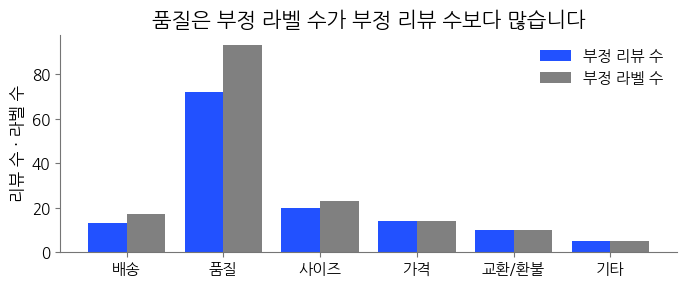

In [13]:
# 단계 3 · 그림: 속성마다 근거 확인 부정 리뷰 수와 부정 라벨 수(앞 200건)
x = np.arange(len(ASPECTS))
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(x - 0.2, [neg_reviews(FIRST_200, a) for a in ASPECTS], width=0.4, color="#2251FF", label="부정 리뷰 수")
ax.bar(x + 0.2, [neg_labels(FIRST_200, a) for a in ASPECTS], width=0.4, color="gray", label="부정 라벨 수")
ax.set_xticks(x, ASPECTS)
ax.set_ylabel("리뷰 수 · 라벨 수")
ax.legend(frameon=False)
ax.set_title("품질은 부정 라벨 수가 부정 리뷰 수보다 많습니다")
plt.show()

**직접 해 보기: 품질 부정 비율의 분모와 값**

- `MY_DENOM`: 품질 부정 비율의 분모(건, 정수)
- `MY_QUALITY_PCT`: 품질 부정 비율(%, 소수 첫째 자리). 예: `MY_QUALITY_PCT = 12.3`

확인 셀을 실행하면 답이 맞는지와 함께 흔한 실수 3가지를 했을 때의 값도 나옵니다.

In [14]:
# 단계 3 · 직접 해 보기: 분모(건) · 품질 부정 비율(%)
MY_DENOM = 200
MY_QUALITY_PCT = 36.0

In [15]:
# 단계 3 · 확인 셀: 분모와 품질 부정 비율, 흔한 실수 3가지의 값
def check_rate(denom, pct):
    if denom is None and pct is None:
        print("아직 채우지 않았습니다. 위 셀의 MY_DENOM · MY_QUALITY_PCT 를 채운 뒤 다시 실행합니다")
        return
    if not isinstance(denom, int) or not isinstance(pct, (int, float)):
        print("고칠 것: MY_DENOM 은 정수(건), MY_QUALITY_PCT 는 % 값(예: 12.3)으로 적습니다")
        return
    n, n_fail = len(FIRST_200), int((FIRST_200["status"] == "기타").sum())
    k = neg_reviews(FIRST_200, "품질")
    right = rnd(100 * k / n, 1)
    if 0 < pct < 1:
        print("고칠 것: % 값으로 적었는지 확인합니다(0.123 이 아니라 12.3 처럼)")
    print(f"분모: {'맞았습니다' if denom == n else '아직 다릅니다'} · 품질 부정 비율: {'맞았습니다' if abs(pct - right) < 0.05 else '아직 다릅니다'}")
    if denom == n and abs(pct - right) < 0.05:
        print(f"근거 확인 품질 부정 리뷰 {k}건 ÷ 보낸 리뷰 {n}건 = {right}%")
    mistakes = [(f"라벨 실패 {n_fail}건을 분모에서 빼면", k, n - n_fail),
                ("보류한 라벨까지 포함하면", neg_reviews(FIRST_200, "품질", True), n),
                ("리뷰 수 대신 라벨 수로 집계하면", neg_labels(FIRST_200, "품질"), n)]
    for text, num, den in mistakes:
        v = rnd(100 * num / den, 1)
        print(f"{text} {num} ÷ {den} = {v}%" + (" · 적은 값과 같습니다" if abs(pct - v) < 0.05 else ""))


check_rate(globals().get("MY_DENOM"), globals().get("MY_QUALITY_PCT"))

분모: 맞았습니다 · 품질 부정 비율: 맞았습니다
근거 확인 품질 부정 리뷰 72건 ÷ 보낸 리뷰 200건 = 36.0%
라벨 실패 3건을 분모에서 빼면 72 ÷ 197 = 36.5%
보류한 라벨까지 포함하면 73 ÷ 200 = 36.5%
리뷰 수 대신 라벨 수로 집계하면 93 ÷ 200 = 46.5%


<details class="lms-extra"><summary>자세히 — 예시 답</summary>

`MY_DENOM = 200` · `MY_QUALITY_PCT = 36.0`. 근거가 확인된 품질 부정 리뷰 72건을 보낸 200건으로 나눈 값입니다.

- 라벨 실패 3건을 빼고 197 로 나누면 36.5% 입니다. 197 로 나누면 라벨 실패 리뷰도 나머지와 같은 비율로 불만이 있다고 보는 셈입니다. 200 으로 나누면 그 3건에 불만이 없다고 본 값이라 가장 작은 값이 됩니다.
- 보류한 라벨까지 포함하면 73건이라 36.5% 입니다. 근거가 원문에 없는 라벨 하나가 포함됩니다.
- 리뷰 수 대신 라벨 수 93개를 분자로 쓰면 46.5% 입니다. 한 리뷰에 품질 부정 라벨이 2개 이상인 리뷰가 있어 크게 나옵니다.

200건으로는 품질 부정 비율이 36.0% 이고 이론에서 본 리뷰 1,000건으로는 35.8% 입니다.

</details>

> **[문제] 라벨 실패와 보류가 함께 있을 때의 분모**
>
> 예를 들어 리뷰 500건을 LLM 에게 보냈다고 합시다. 재시도 뒤에도 형식을 어긴 리뷰(라벨 실패)가 10건이고, 근거 텍스트가 원문에 없어 보류한 라벨이 20개입니다. 품질 부정 비율의 분모는 몇 건일까요?
>
> 1. 490건: 라벨 실패 리뷰는 라벨이 없으니 뺀다
> 2. 500건: 라벨 실패 리뷰도 보낸 리뷰라 남긴다
> 3. 470건: 라벨 실패 10건과 보류 20개를 모두 뺀다

> **[문제] 다른 분기의 비율과 비교하기 전에 확인할 것**
>
> 예를 들어 동료가 다음 분기 리뷰 1,000건을 LLM 으로 라벨링해 「품질 부정 41%」를 보내왔습니다. 이번 분기 35.8% 와 비교하기 전에 확인할 것 세 가지를 적고, 그 가운데 하나를 골라 이유를 한 문장으로 적어 보세요.

## 단계 4 전임 담당자의 집계 고치기

전임 담당자는 Qwen2.5-0.5B 의 출력 2,000건으로 「사이즈 불만 15.93%」라는 결론을 냈습니다. 아래 셀이 그 집계 코드입니다. 오류 없이 실행되지만 비율이 틀렸습니다. 코드를 실행하고, 단계 2 · 3 에서 본 것과 무엇이 다른지 찾습니다.

In [16]:
# 단계 4: 전임 담당자의 집계 코드(그대로 실행합니다)
ok_rows = []                                              # 형식을 통과한 출력만 모은다
for raw, text in zip(PRED["raw"], PRED["본문"]):
    chk = check_output(raw, text)                         # 파싱 → 스키마 검증
    if chk["ok"]:
        ok_rows.append(chk["parsed"]["aspects"])
n_ok = len(ok_rows)                                       # 분모 = 형식을 통과한 출력 수


def old_count(aspect):
    # 그 속성의 부정 라벨이 있는 리뷰 수
    return sum(any(x["aspect"] == aspect and x["polarity"] == "부정" for x in labels) for labels in ok_rows)


print(f"결론: 사이즈 불만 {rnd(100 * old_count('사이즈') / n_ok, 2)}% · 품질 불만 {rnd(100 * old_count('품질') / n_ok, 1)}%")
print(f"분모: 형식을 통과한 출력 {n_ok}건")
for a in ASPECTS:
    print(f"{a}: 부정 리뷰 {old_count(a)}건 · {rnd(100 * old_count(a) / n_ok, 2)}%")

결론: 사이즈 불만 15.93% · 품질 불만 41.3%
분모: 형식을 통과한 출력 816건
배송: 부정 리뷰 179건 · 21.94%
품질: 부정 리뷰 337건 · 41.3%
사이즈: 부정 리뷰 130건 · 15.93%
가격: 부정 리뷰 59건 · 7.23%
교환/환불: 부정 리뷰 27건 · 3.31%
기타: 부정 리뷰 1건 · 0.12%


분모 816건은 형식을 통과한 출력 수이고, 나머지 1,184건은 파싱이나 스키마 검증을 통과하지 못했습니다.

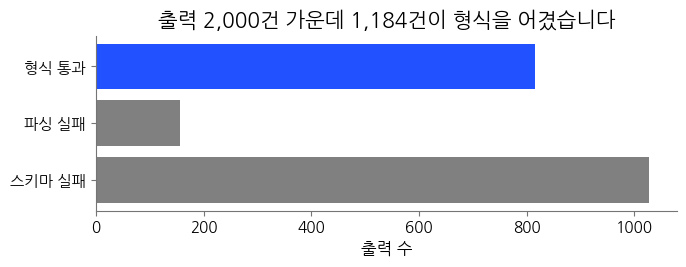

In [17]:
# 단계 4 · 그림: 전임 담당자의 출력 2,000건의 검사 결과
n_parse = sum(extract_json(r) is None for r in PRED["raw"])     # JSON 으로 읽히지 않은 출력
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(["형식 통과", "파싱 실패", "스키마 실패"], [n_ok, n_parse, N_SENT - n_ok - n_parse], color=["#2251FF", "gray", "gray"])
ax.invert_yaxis()
ax.set_xlabel("출력 수")
ax.set_title(f"출력 {N_SENT:,}건 가운데 {N_SENT - n_ok:,}건이 형식을 어겼습니다")
plt.show()

**직접 해 보기: 틀린 곳과 고친 사이즈 부정 비율**

`MY_ERRORS` 에는 아래 보기 가운데 틀린 곳 두 개의 번호를 적습니다.

1. 분모로 형식을 통과한 출력 수를 썼다
2. 근거 텍스트가 원문에 있는지 확인하지 않았다
3. 코드 펜스(```json)로 감싼 출력을 파싱하지 못했다
4. 같은 속성의 부정 라벨을 리뷰마다 한 번만 집계했다
5. 극성이 중립인 라벨을 부정으로 집계했다

`MY_SIZE_PCT` 에는 두 곳을 고친 사이즈 부정 비율(%, 소수 둘째 자리)을 적습니다. 값은 아래 셀에서 직접 계산합니다. 분모로 쓸 보낸 리뷰 수는 `N_SENT` 에 있습니다.

In [18]:
# 단계 4 · 계산: 근거가 확인된 사이즈 부정 라벨이 있는 리뷰 수와 보낸 리뷰 수
size_ok = 0
for raw, text in zip(PRED["raw"], PRED["본문"]):
    chk = check_output(raw, text)
    if chk["ok"] and any(x["aspect"] == "사이즈" and x["polarity"] == "부정" and evidence_in_text(x["evidence"], text)
                         for x in chk["parsed"]["aspects"]):
        size_ok += 1
print(f"근거 확인 사이즈 부정 리뷰 {size_ok}건 · 보낸 리뷰 {N_SENT:,}건 · 형식을 통과한 출력 {n_ok}건")

근거 확인 사이즈 부정 리뷰 79건 · 보낸 리뷰 2,000건 · 형식을 통과한 출력 816건


In [19]:
# 단계 4 · 직접 해 보기: 틀린 곳 보기 번호 두 개 · 고친 사이즈 부정 비율(%)
MY_ERRORS = [1, 2]
MY_SIZE_PCT = 3.95

In [20]:
# 단계 4 · 확인 셀: 틀린 곳 두 개와 고친 사이즈 부정 비율
WHY_NOT = {3: "extract_json 이 코드 펜스를 지웁니다. 단계 2 의 출력 5 도 펜스가 있었지만 통과했습니다",
           4: "any(…) 로 리뷰마다 한 번만 집계한 것은 맞는 방법입니다",
           5: "코드는 극성이 「부정」인 라벨만 집계합니다"}


def check_fix(errors, size_pct):
    if not errors and size_pct is None:
        print("아직 채우지 않았습니다. 위 셀의 MY_ERRORS · MY_SIZE_PCT 를 채운 뒤 다시 실행합니다")
        return
    if not all(e in (1, 2, 3, 4, 5) for e in errors) or not isinstance(size_pct, (int, float)):
        print("고칠 것: MY_ERRORS 는 보기 번호(1～5) 목록, MY_SIZE_PCT 는 % 값(예: 1.23)으로 적습니다")
        return
    right = rnd(100 * size_ok / N_SENT, 2)
    if 0 < size_pct < 1:
        print("고칠 것: % 값으로 적었는지 확인합니다(0.0123 이 아니라 1.23 처럼)")
    print("틀린 곳: " + ("맞았습니다" if set(errors) == {1, 2} else "아직 다릅니다. 두 개를 모두 골랐는지 봅니다"))
    for e in sorted(set(errors) - {1, 2}):
        print(f"  보기 {e}: 틀린 곳이 아닙니다. {WHY_NOT[e]}")
    print("사이즈 부정 비율: " + ("맞았습니다" if abs(size_pct - right) < 0.005 else "아직 다릅니다"))
    half = {"분모만 보낸 리뷰 수로 바꾸면": rnd(100 * old_count("사이즈") / N_SENT, 2),
            "근거 확인만 더하면": rnd(100 * size_ok / n_ok, 2)}
    for text, v in half.items():
        if abs(size_pct - v) < 0.005:
            print(f"  {text} {v}% 입니다. 두 곳을 모두 고칩니다")
    if abs(size_pct - right) < 0.005:
        print(f"근거 확인 사이즈 부정 리뷰 {size_ok}건 ÷ 보낸 리뷰 {N_SENT:,}건 = {right}%")
        print(f"{right}% 는 라벨 실패 {N_SENT - n_ok:,}건에 사이즈 불만이 하나도 없다고 볼 때의 가장 작은 값입니다")


check_fix(globals().get("MY_ERRORS", []), globals().get("MY_SIZE_PCT"))

틀린 곳: 맞았습니다
사이즈 부정 비율: 맞았습니다
근거 확인 사이즈 부정 리뷰 79건 ÷ 보낸 리뷰 2,000건 = 3.95%
3.95% 는 라벨 실패 1,184건에 사이즈 불만이 하나도 없다고 볼 때의 가장 작은 값입니다


고친 비율은 라벨 실패 1,184건에 사이즈 불만이 하나도 없다고 볼 때의 가장 작은 값입니다. 라벨 실패가 출력의 절반을 넘어, 전임 담당자의 출력으로는 사이즈 부정 비율을 쓸 수 없습니다. 라벨 실패가 19건뿐인 Qwen3-4B 라벨의 9.2%(7.4～11.0%)를 씁니다.

<details class="lms-extra"><summary>자세히 — 예시 답</summary>

`MY_ERRORS = [1, 2]` · `MY_SIZE_PCT = 3.95`. 근거가 확인된 사이즈 부정 리뷰 79건을 보낸 2,000건으로 나눈 값입니다.

- 분모만 2,000 으로 바꾸면 130 ÷ 2,000 = 6.50% 입니다. 근거 확인만 더하면 79 ÷ 816 ≈ 9.68% 입니다.
- 형식을 어긴 출력 1,184건은 라벨 실패이고 보낸 리뷰의 59.2% 입니다. 3.95% 는 라벨이 남은 816건 안에서 확인된 값입니다.
- Qwen3-4B 라벨로 리뷰 1,000건을 집계하면 사이즈 부정은 9.2% 입니다.

라벨 실패 건수를 모르면 3.95% 가 가장 작은 값인지 알 수 없습니다. 모델 이름 · 모델 버전 · 프롬프트 버전은 그 비율을 어떤 라벨로 구했는지 나타냅니다.

</details>

## 단계 5 만족한 리뷰의 불만

별점 4·5점을 준 고객도 불만을 적습니다. 리뷰 161542 도 별점은 5점이지만 품질 부정 라벨이 있습니다. 별점 4·5점 리뷰만 골라 어느 속성의 불만이 가장 많은지 봅니다. 먼저 리뷰 전체 극성을 별점과 비교합니다.

**선택형 극성**은 리뷰 전체 극성을 「긍정」 · 「부정」 두 단어 가운데 고르게 해 구한 값입니다. 생성한 글을 읽지 않아 형식 실패가 없고 2만 건 모두에 값이 있습니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/4/4b/Softmax.svg" alt="개 그림이 CNN 상자로 들어가 Chat 35.4, Chien 38.1, Cheval -5.0 세 점수가 나오고, Softmax 상자를 지나 Chat 0.06, Chien 0.94, Cheval 0.00 세 확률이 되는 그림" width="560" height="233"/>
<p align="center"><em>▲ 분류 모델이 낸 점수 3개를 소프트맥스(softmax)가 합이 1 인 확률로 바꾼다. 선택형 극성은 「긍정」 「부정」 두 단어의 점수로 같은 계산을 해 큰 쪽을 고른다 (출처: Wikimedia Commons 「Softmax.svg」, Fschwarzentruber, CC BY-SA 4.0)</em></p>

리뷰 표본 2만 건에서 선택형 극성을 별점 극성과 비교합니다.

In [21]:
# 단계 5: 리뷰 표본 2만 건의 선택형 극성 × 별점 극성(건)
cross = pd.crosstab(OVERALL_20K["overall"], OVERALL_20K["극성"])
agree = (cross.loc["부정", "부정"] + cross.loc["긍정", "긍정"]) / len(OVERALL_20K)
print("표 2 · 리뷰 전체 극성과 별점 극성 (리뷰 표본 2만 건, 건)")
for llm in ["부정", "긍정"]:
    print(f"LLM {llm}: 별점 1·2점 {cross.loc[llm, '부정']:,}건 · 별점 4·5점 {cross.loc[llm, '긍정']:,}건")
print(f"합: 별점 1·2점 {cross['부정'].sum():,}건 · 별점 4·5점 {cross['긍정'].sum():,}건")
print(f"일치율 {agree:.2f} · 늘 「부정」이라고만 답할 때 {cross['부정'].sum() / len(OVERALL_20K):.2f}")

표 2 · 리뷰 전체 극성과 별점 극성 (리뷰 표본 2만 건, 건)
LLM 부정: 별점 1·2점 9,311건 · 별점 4·5점 967건
LLM 긍정: 별점 1·2점 636건 · 별점 4·5점 9,086건
합: 별점 1·2점 9,947건 · 별점 4·5점 10,053건
일치율 0.92 · 늘 「부정」이라고만 답할 때 0.50


일치율은 선택형 극성과 별점 극성이 일치하는 리뷰의 비율입니다. 늘 「부정」이라고만 답해도 0.50 이 나오므로, 일치율은 이 값과 비교해야 높은지 알 수 있습니다.

> **[문제] 별점과 일치하는 리뷰의 비율**
>
> 단계 5 의 첫 셀을 실행하면 나오는 「표 2 · 리뷰 전체 극성과 별점 극성 (리뷰 표본 2만 건, 건)」을 봅니다. 이 표에서 맞는 설명은 무엇일까요?
>
> 1. LLM 이 별점과 일치하는 리뷰가 약 92% 로, 늘 「부정」만 답할 때보다 높다
> 2. LLM 의 리뷰 전체 극성은 약 92% 가 맞고 약 8% 가 틀렸다
> 3. 별점이 본문과 반대인 리뷰가 약 8% 있다

속성별 부정 비율은 95% 구간이 있어야 순위를 말할 수 있습니다. 리뷰 1,000건 전체부터 계산합니다.

- 분모는 리뷰 수(라벨 실패 포함)이고, 분자는 근거가 확인된 부정 라벨이 있는 리뷰 수입니다.
- 오차 한계는 1.96 × √(비율 × (1 − 비율) ÷ 리뷰 수) 입니다. 아래 끝이 0 보다 작으면 0 으로 표시합니다.
- 두 속성의 구간이 겹치지 않을 때만 어느 쪽이 크다고 말합니다. 그림의 점은 부정 비율, 가로선은 95% 구간입니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/8/8f/NYW-confidence-interval.svg" alt="가로로 늘어선 파란 세로 선분 50개와 그 가운데를 지나는 분홍 점선 μ. 선분 대부분이 점선을 가로지르고 몇 개는 점선 위나 아래에서 끝난다" width="560" height="230"/>
<p align="center"><em>▲ 같은 모집단에서 표본을 50번 골라 만든 95% 구간 50개. 대부분은 분홍 점선의 참값 μ 를 지나고 몇 개는 점선과 만나지 않는다. 다른 리뷰 1,000건을 라벨링하면 속성별 부정 비율도 조금씩 달라진다 (출처: Wikimedia Commons 「NYW-confidence-interval.svg」, Tsyplakov, 퍼블릭 도메인)</em></p>

표 3 · 리뷰 1,000건의 속성별 부정 비율과 95% 구간 (%)
품질: 35.8% (32.8～38.8%) · 부정 리뷰 358건
사이즈: 9.2% (7.4～11.0%) · 부정 리뷰 92건
배송: 7.5% (5.9～9.1%) · 부정 리뷰 75건
가격: 5.0% (3.6～6.4%) · 부정 리뷰 50건
교환/환불: 3.8% (2.6～5.0%) · 부정 리뷰 38건
기타: 2.2% (1.3～3.1%) · 부정 리뷰 22건


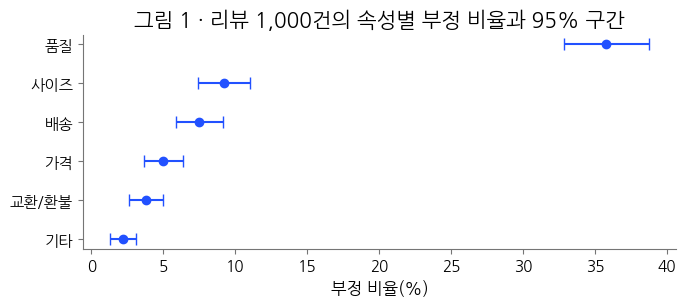

In [22]:
# 단계 5: 속성별 부정 비율과 95% 구간(리뷰 1,000건 전체)
def aspect_table(df):
    # 속성마다 근거가 확인된 부정 라벨이 있는 리뷰의 비율(%)과 95% 구간. 분모는 df 의 리뷰 수(라벨 실패 포함)
    n = len(df)
    k = np.array([neg_reviews(df, a) for a in ASPECTS])
    p = k / n
    half = 1.96 * np.sqrt(p * (1 - p) / n)                     # 오차 한계
    t = pd.DataFrame({"aspect": ASPECTS, "k": k, "pct": 100 * p,
                      "low": np.maximum(0, 100 * (p - half)), "high": 100 * (p + half)})
    return t.sort_values("pct", ascending=False).reset_index(drop=True)


def print_table(t, title):
    print(title)
    for _, r in t.iterrows():
        print(f"{r['aspect']}: {rnd(r['pct'], 1)}% ({rnd(r['low'], 1)}～{rnd(r['high'], 1)}%) · 부정 리뷰 {r['k']}건")


def plot_ci(t, title):
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.errorbar(t["pct"], t["aspect"], xerr=[t["pct"] - t["low"], t["high"] - t["pct"]], fmt="o", capsize=4, color="#2251FF")
    ax.invert_yaxis()                                          # 부정 비율이 큰 속성을 맨 위에
    ax.set_xlabel("부정 비율(%)")
    ax.set_title(title)
    plt.show()


ALL_TABLE = aspect_table(LABELS_1000)
print_table(ALL_TABLE, "표 3 · 리뷰 1,000건의 속성별 부정 비율과 95% 구간 (%)")
plot_ci(ALL_TABLE, "그림 1 · 리뷰 1,000건의 속성별 부정 비율과 95% 구간")

리뷰 1,000건에서는 품질 부정이 가장 많고, 품질의 아래 끝이 다른 5개 속성의 위 끝보다 큽니다.

> **[문제] 품질 다음으로 많은 불만 속성**
>
> 단계 5 의 둘째 셀을 실행하면 나오는 「표 3 · 리뷰 1,000건의 속성별 부정 비율과 95% 구간 (%)」과 「그림 1 · 리뷰 1,000건의 속성별 부정 비율과 95% 구간」을 봅니다. 품질 다음으로 많은 불만 속성은 어떻게 쓸까요?
>
> 1. 사이즈라고 쓴다: 부정 비율이 배송보다 크다
> 2. 정하지 않는다: 사이즈와 배송의 구간이 겹친다
> 3. 사이즈와 배송이 같다고 쓴다: 구간이 겹친다

같은 계산을 별점 4·5점 리뷰에만 합니다. 분모는 리뷰 1,000건 가운데 별점 4·5점인 리뷰 수입니다(라벨 실패 포함). 같은 비율이라면 리뷰 수가 줄수록 구간이 넓어지지만, 표 4 는 비율 자체가 작아 구간이 표 3 보다 좁게 나옵니다.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/6/63/Margin_of_error_vs_sample_size_and_confidence_level.svg/960px-Margin_of_error_vs_sample_size_and_confidence_level.svg.png" alt="가로축 표본 크기 n 10 부터 10만, 세로축 오차 한계 0.1 부터 100 퍼센트인 로그 스케일 그래프. 신뢰 수준마다 오른쪽 아래로 내려가는 평행한 직선이 있고, 검은 점선이 95% 이다. n = 1000 에서 95% 는 3.1, 99% 는 4.1 이라고 화살표로 표시되어 있고, 오른쪽 위 작은 그림은 p 에 따른 보정 계수 곡선이다" width="560" height="420"/>
<p align="center"><em>▲ 가로축은 표본 크기 n, 세로축은 비율의 최대 오차 한계(±%)이고 가로축 · 세로축 모두 로그 스케일이다. 직선 하나가 신뢰 수준 하나이고 검은 점선이 95% 구간이다. 표본이 작을수록 오차 한계가 크다 (출처: Wikimedia Commons, Margin of error vs sample size and confidence level.svg, Cmglee, CC BY-SA 4.0)</em></p>

별점 4·5점 리뷰 482건(라벨 실패 9건 포함)
표 4 · 별점 4·5점 리뷰의 속성별 부정 비율과 95% 구간 (%)
품질: 8.1% (5.7～10.5%) · 부정 리뷰 39건
사이즈: 3.5% (1.9～5.2%) · 부정 리뷰 17건
배송: 2.7% (1.3～4.1%) · 부정 리뷰 13건
기타: 0.6% (0.0～1.3%) · 부정 리뷰 3건
가격: 0.4% (0.0～1.0%) · 부정 리뷰 2건
교환/환불: 0.4% (0.0～1.0%) · 부정 리뷰 2건


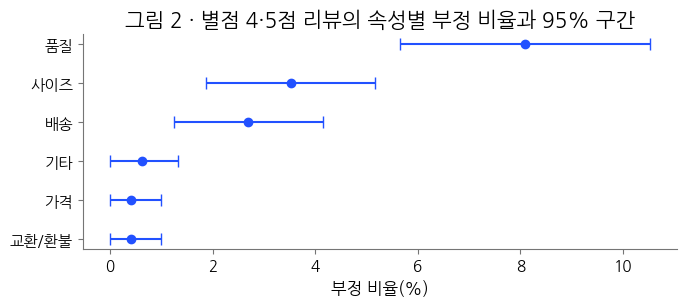

In [23]:
# 단계 5: 별점 4·5점 리뷰만 골라 속성별 부정 비율과 95% 구간
HAPPY = LABELS_1000[LABELS_1000["별점"] >= 4]
HAPPY_TABLE = aspect_table(HAPPY)
print(f"별점 4·5점 리뷰 {len(HAPPY)}건(라벨 실패 {int((HAPPY['status'] == '기타').sum())}건 포함)")
print_table(HAPPY_TABLE, "표 4 · 별점 4·5점 리뷰의 속성별 부정 비율과 95% 구간 (%)")
plot_ci(HAPPY_TABLE, "그림 2 · 별점 4·5점 리뷰의 속성별 부정 비율과 95% 구간")

**직접 해 보기: 만족한 리뷰에서 가장 많은 불만**

- `MY_TOP`: 별점 4·5점 리뷰에서 부정 비율이 가장 큰 속성. 예: `MY_TOP = "배송"`
- `MY_ORDER_OK`: 그 속성이 2위 속성보다 크다고 말할 수 있으면 `True`, 아니면 `False`

표 4 의 두 구간을 비교해 정합니다. 확인 셀은 구간이 겹치는지로 판단하고 1위 속성의 아래 끝과 2위 속성의 위 끝도 보여 줍니다.

In [24]:
# 단계 5 · 직접 해 보기: 가장 많은 속성 · 2위보다 크다고 말할 수 있는가
MY_TOP = '품질'
MY_ORDER_OK = True

In [25]:
# 단계 5 · 확인 셀: 가장 많은 속성과, 2위 속성과의 95% 구간 겹침
def check_order(top, order_ok):
    if top is None and order_ok is None:
        print("아직 채우지 않았습니다. 위 셀의 MY_TOP · MY_ORDER_OK 를 채운 뒤 다시 실행합니다")
        return
    if top not in ASPECTS or not isinstance(order_ok, bool):
        print("고칠 것: MY_TOP 은 코드북 v1 의 속성 이름, MY_ORDER_OK 는 True 나 False 로 적습니다")
        return
    first, second = HAPPY_TABLE.iloc[0], HAPPY_TABLE.iloc[1]
    apart = first["low"] > second["high"]                      # 구간이 겹치지 않는가
    print("가장 많은 속성: " + ("맞았습니다" if top == first["aspect"] else "아직 다릅니다. 표 4 의 첫 줄을 봅니다"))
    print("2위보다 크다고 말할 수 있는가: " + ("맞았습니다" if order_ok == apart else "아직 다릅니다"))
    word = "커서 구간이 겹치지 않습니다" if apart else "크지 않아 구간이 겹칩니다"
    print(f"{first['aspect']}의 아래 끝 {rnd(first['low'], 1)}% 가 {second['aspect']}의 위 끝 {rnd(second['high'], 1)}% 보다 {word}")


check_order(globals().get("MY_TOP"), globals().get("MY_ORDER_OK"))

가장 많은 속성: 맞았습니다
2위보다 크다고 말할 수 있는가: 맞았습니다
품질의 아래 끝 5.7% 가 사이즈의 위 끝 5.2% 보다 커서 구간이 겹치지 않습니다


<details class="lms-extra"><summary>자세히 — 예시 답</summary>

`MY_TOP = "품질"` · `MY_ORDER_OK = True`

- 별점 4·5점 리뷰 482건 가운데 품질 부정은 8.1%(5.7～10.5%)입니다.
- 2위인 사이즈는 3.5%(1.9～5.2%)입니다. 품질의 아래 끝 5.7% 가 사이즈의 위 끝 5.2% 보다 커서, 품질이 사이즈보다 크다고 말할 수 있습니다.
- 사이즈와 배송은 구간이 겹쳐 순위를 정하지 않습니다.

만족한 고객도 품질 불만을 가장 많이 적습니다. 별점이 높다고 불만이 없는 것은 아니어서, 별점만으로는 속성 불만을 알 수 없습니다.

</details>

## 결론

위 막대 2개는 전임 담당자의 출력(Qwen2.5-0.5B, 라벨 실패 1,184건)으로 구한 사이즈 부정 비율입니다. 맨 아래 막대는 고친 계산법을 Qwen3-4B 라벨(라벨 실패 19건)에 적용한 값입니다.

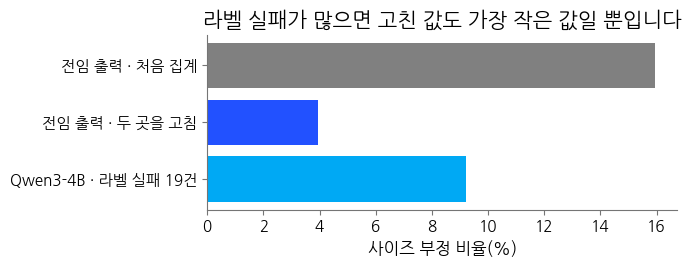

In [26]:
# 결론 · 그림: 사이즈 부정 비율, 계산마다
names = ["전임 출력 · 처음 집계", "전임 출력 · 두 곳을 고침", "Qwen3-4B · 라벨 실패 19건"]
vals = [100 * old_count("사이즈") / n_ok, 100 * size_ok / N_SENT, ALL_TABLE.set_index("aspect").loc["사이즈", "pct"]]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(names, vals, color=["gray", "#2251FF", "#00A9F4"])
ax.invert_yaxis()
ax.set_xlabel("사이즈 부정 비율(%)")
ax.set_title("라벨 실패가 많으면 고친 값도 가장 작은 값일 뿐입니다")
plt.show()

<div class="lms-summary">

**정리**

- 코드북: 라벨은 (속성, 극성)이고 한 리뷰에 여럿일 수 있습니다. 애매한 리뷰는 어느 속성으로 정했는지를 그 속성의 포함 기준이나 다른 속성의 제외 기준에 반영합니다.
- 출력 확인: 형식을 어긴 출력은 라벨 실패, 근거 텍스트가 원문에 없는 라벨은 보류입니다. 근거 텍스트 확인은 글자만 비교합니다.
- 분모: 품질 부정 비율은 근거가 확인된 품질 부정 리뷰 수 ÷ 보낸 리뷰 수입니다. 앞 200건이면 36.0% 입니다.
- 전임 담당자의 15.93% 는 두 곳을 고치면 3.95% 입니다. 라벨 실패가 많아 가장 작은 값일 뿐이라 Qwen3-4B 의 9.2% 를 씁니다.
- 일치율 0.92 는 정확도가 아닙니다. 높은지는 늘 「부정」이라고만 답한 0.50 과 비교해 판단합니다.
- 순위: 두 속성의 95% 구간이 겹치지 않을 때만 순위를 말합니다. 별점 4·5점 리뷰에서도 품질 부정이 가장 많습니다.

리뷰의 불만은 품질에 가장 많습니다. LLM 라벨로 구한 비율은 형식 · 근거 텍스트 · 분모를 확인한 뒤에 씁니다.

</div>

> **[과제] 실습 제출: 리뷰 속성별 부정 비율과 고친 집계**
>
> 직접 해 보기에서 ① 단계 1 의 MY_LABELS ② 단계 2 의 MY_FAIL · MY_HOLD ③ 단계 3 의 MY_DENOM · MY_QUALITY_PCT ④ 단계 4 의 MY_ERRORS · MY_SIZE_PCT ⑤ 단계 5 의 MY_TOP · MY_ORDER_OK 를 채웁니다. 확인 셀을 실행한 상태로 노트북을 제출합니다. 단계 1 은 Qwen3-4B 의 라벨과 달라도 확인 셀이 결과를 출력했으면 점수를 받습니다.
>
> 마감: 2026-11-10T23:59+09:00
>
> **평가 기준**
>
> | 기준 | 이렇게 하면 충족 | 배점 |
> | --- | --- | --- |
> | 단계 1 | 리뷰 5건의 라벨을 모두 적었고 확인 셀이 리뷰마다 결과를 출력했다(Qwen3-4B 라벨과 달라도 점수) | 20 |
> | 단계 2 | MY_FAIL · MY_HOLD 를 채웠고 확인 셀이 두 변수 모두 맞았다고 출력했다 | 20 |
> | 단계 3 | MY_DENOM · MY_QUALITY_PCT 를 채웠고 확인 셀이 두 변수 모두 맞았다고 출력했다 | 20 |
> | 단계 4 | MY_ERRORS · MY_SIZE_PCT 를 채웠고 확인 셀이 두 변수 모두 맞았다고 출력했다 | 20 |
> | 단계 5 | MY_TOP · MY_ORDER_OK 를 채웠고 확인 셀이 두 변수 모두 맞았다고 출력했다 | 20 |
>
> 제출은 LMS 레슨 화면의 과제 카드에서 GitHub 링크로 합니다(이 파일에 적으면 제출되지 않습니다).

<div style="background:#F2F2F2;color:#000000;padding:28px;border-radius:12px;border:1px solid #E6E6E6;margin-top:16px;border-left:4px solid #051C2C">
<h2 style="color:#000000;margin:0 0 8px 0">수고했습니다. 비정형 데이터(자연어) LLM 라벨링 실습을 마쳤습니다</h2>
<div style="color:#656565">코드북으로 라벨을 정하고, LLM 출력의 형식과 근거 텍스트를 확인했습니다. 보낸 리뷰 수로 비율을 구하고, 전임 담당자의 「사이즈 불만 15.93%」도 고쳤습니다.</div>
</div>